In [1]:
!python -V

Python 3.14.0


In [2]:
import pandas as pd

In [3]:
import pickle

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline

from sklearn.metrics import root_mean_squared_error

In [ ]:
import mlflow

mlflow.set_tracking_uri("sqlite:///../mlflow.db")
mlflow.set_experiment("nyc-taxi-experiment")

2026/10/11 19:16:13 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/11 19:16:13 INFO mlflow.store.db.utils: Updating database tables
2026/10/11 19:16:14 INFO mlflow.tracking.fluent: Experiment with name 'nyc-taxi-experiment' does not exist. Creating a new experiment.


<Experiment: artifact_location='/Users/fabrizioboninsegna/Projects/MLOps-Zoomcamp/notebooks/mlruns/1', creation_time=1791738974302, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1791738974302, lifecycle_stage='active', name='nyc-taxi-experiment', tags={}, trace_location=None, workspace='default'>

In [7]:
df = pd.read_parquet('./data/green_tripdata_2026-01.parquet')

df['duration'] = df.lpep_dropoff_datetime - df.lpep_pickup_datetime
df.duration = df.duration.apply(lambda td: td.total_seconds() / 60)

df = df[(df.duration >= 1) & (df.duration <= 60)]

categorical = ['PULocationID', 'DOLocationID']
numerical = ['trip_distance']
target = 'duration'

df[categorical] = df[categorical].astype(str)

In [8]:
X_train = df[categorical + numerical]
y_train = df[target]

preprocess = ColumnTransformer(
    transformers= [
        ('num', StandardScaler(), numerical),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical)
    ]
)

lr_model = make_pipeline(
    preprocess,
    LinearRegression()
)

lr_model.fit(X_train, y_train)

y_pred = lr_model.predict(X_train)

root_mean_squared_error(y_train, y_pred)

8.016462735675553

/var/folders/4r/57_hcrzs18x0zbv25988w4pc0000gn/T/ipykernel_82495/1672306066.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(y_pred, label='prediction')
/var/folders/4r/57_hcrzs18x0zbv25988w4pc0000gn/T/ipykernel_82495/1672306066.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(y_train, lab

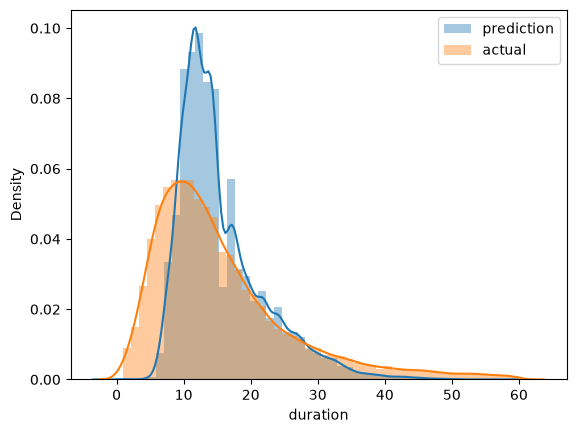

In [9]:
sns.distplot(y_pred, label='prediction')
sns.distplot(y_train, label='actual')

plt.legend()

In [10]:
def read_dataframe(filename):
    if filename.endswith('.csv'):
        df = pd.read_csv(filename)

        df.lpep_dropoff_datetime = pd.to_datetime(df.lpep_dropoff_datetime)
        df.lpep_pickup_datetime = pd.to_datetime(df.lpep_pickup_datetime)
    elif filename.endswith('.parquet'):
        df = pd.read_parquet(filename)

    df['duration'] = df.lpep_dropoff_datetime - df.lpep_pickup_datetime
    df.duration = df.duration.apply(lambda td: td.total_seconds() / 60)

    df = df[(df.duration >= 1) & (df.duration <= 60)]

    categorical = ['PULocationID', 'DOLocationID']
    df[categorical] = df[categorical].astype(str)
    
    return df

df_train = read_dataframe('./data/green_tripdata_2026-01.parquet')
df_val = read_dataframe('./data/green_tripdata_2026-02.parquet')

len(df_train), len(df_val)

df_train['PU_DO'] = df_train['PULocationID'] + '_' + df_train['DOLocationID']
df_val['PU_DO'] = df_val['PULocationID'] + '_' + df_val['DOLocationID']

categorical = ['PU_DO'] #'PULocationID', 'DOLocationID']
numerical = ['trip_distance']

X_train = df_train[categorical + numerical]
X_val = df_val[categorical + numerical]

target = 'duration'
y_train = df_train[target]
y_val = df_val[target]

In [11]:
with mlflow.start_run():

    mlflow.set_tag("developer", "fabrizioboninsegna")

    mlflow.log_param("model-type", "LinearRegression")
    mlflow.log_param("train-data-path", "./data/green_tripdata_2026-01.parquet")
    mlflow.log_param("valid-data-path", "./data/green_tripdata_2026-02.parquet")

    preprocess = ColumnTransformer(
        transformers= [
            ('num', StandardScaler(), numerical),
            ('cat', OneHotEncoder(handle_unknown='ignore'), categorical)
        ]
    )

    lr_model = make_pipeline(
        preprocess,
        LinearRegression()
    )

    lr_model.fit(X_train, y_train)

    y_pred = lr_model.predict(X_val)

    rmse = root_mean_squared_error(y_val, y_pred)
    mlflow.log_metric("rmse", rmse)

In [12]:
import joblib

# Save the entire pipeline as one object
joblib.dump(lr_model, 'models/lin_reg_pipeline.bin')

['models/lin_reg_pipeline.bin']